# Data Understanding, Quality and EDA

Goal: understand the student-feedback dataset before applying any ML or NLP method.

We want to find out:
- what the dataset contains
- whether categories and sentiment labels are balanced
- whether feedback is single-theme or multi-theme
- what data-quality problems exist (missing, empty, duplicate, very short)
- what privacy / PII risks exist
- whether the current category taxonomy is suitable for modelling

Outputs are written to `data/processed/` (tables, review queues, cleaned dataset, summary report) and `data/processed/plots/`.

## 0. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

OUT = Path("../data/processed")
PLOTS = OUT / "plots"
PLOTS.mkdir(parents=True, exist_ok=True)

## 1. Load the dataset

In [2]:
df = pd.read_csv("hf://datasets/Hannes111/student_feedback_sentiment/student_feedback_sentiment.csv")

/home/riccha/Documents/practice-agentic-ai/student-feedback-intelligence/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
df.head(10)

,text,category,sentiment_score,sentiment
0,all these are good,examination,1,positive
1,Satisfactory,library_facilities,1,positive
2,very good.,library_facilities,1,positive
3,"it is quite good , depends upon teacher and th...",teaching,1,positive
4,Yes,labwork,1,positive
5,Our university has lot of extracurricular goin...,extracurricular,1,positive
6,excellent,teaching,1,positive
7,"Teaching is excellent,but lecture delivery is ...",teaching,1,positive
8,I like the question pattern,examination,1,positive
9,ALL PRACTICAL WORK IS GOOD,labwork,1,positive


## 2. Inspect: size, columns, categories, sentiment labels

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 724 entries, 0 to 723
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   text             724 non-null    str  
 1   category         724 non-null    str  
 2   sentiment_score  724 non-null    int64
 3   sentiment        724 non-null    str  
dtypes: int64(1), str(3)
memory usage: 77.3 KB


In [5]:
print(df["category"].unique())
print(df["sentiment"].unique())

<ArrowStringArray>
[       'examination', 'library_facilities',           'teaching',
            'labwork',    'extracurricular',     'course_content']
Length: 6, dtype: str
<ArrowStringArray>
['positive', 'negative', 'neutral']
Length: 3, dtype: str


## 3. Data-quality checks

Check missing values first, then strip whitespace and flag empty, very short and duplicate comments.

### 3a. Missing values

In [6]:
df.isna().sum()

text               0
category           0
sentiment_score    0
sentiment          0
dtype: int64

Strip whitespace, then flag empty, duplicate and very short (<= 3 words) comments.

In [7]:
df["text"] = df["text"].str.strip()
df["word_count"] = df["text"].str.split().str.len()

df["is_empty"] = df["text"] == ""
df["is_duplicate"] = df.duplicated(subset="text", keep=False)
df["is_very_short"] = df["word_count"] <= 3

df[["is_empty", "is_duplicate", "is_very_short"]].sum()

is_empty           0
is_duplicate     124
is_very_short    238
dtype: int64

### 3b. Duplicates

Duplicate responses can bias theme-frequency estimates.

In [8]:
df[df["is_duplicate"]].sort_values("text").head(20)

,text,category,sentiment_score,sentiment,word_count,is_empty,is_duplicate,is_very_short
437,Accurate,course_content,1,positive,1,False,True,True
532,Accurate,examination,1,positive,1,False,True,True
617,Accurate,teaching,1,positive,1,False,True,True
346,All good,extracurricular,1,positive,2,False,True,True
624,All good,labwork,1,positive,2,False,True,True
54,Average,examination,0,neutral,1,False,True,True
281,Average,library_facilities,0,neutral,1,False,True,True
419,Average,extracurricular,0,neutral,1,False,True,True
551,Average,labwork,0,neutral,1,False,True,True
447,Awesome,extracurricular,1,positive,1,False,True,True


### 3c. Very short comments

In [9]:
df[df["is_very_short"]].head(20)

,text,category,sentiment_score,sentiment,word_count,is_empty,is_duplicate,is_very_short
1,Satisfactory,library_facilities,1,positive,1,False,False,True
2,very good.,library_facilities,1,positive,2,False,True,True
4,Yes,labwork,1,positive,1,False,True,True
6,excellent,teaching,1,positive,1,False,True,True
10,Not so good,examination,-1,negative,3,False,False,True
11,all are good,teaching,1,positive,3,False,True,True
13,everything is good,teaching,1,positive,3,False,False,True
17,very good,labwork,1,positive,2,False,True,True
19,They are extraordinary,extracurricular,1,positive,3,False,False,True
30,it is ok,teaching,1,positive,3,False,False,True


### 3d. Possible PII

Regex screen for emails, URLs and long digit runs (phone numbers, student IDs). This only flags rows for human review. It doesn't prove PII is present, and it will miss names.

In [10]:
df["possible_pii"] = df["text"].str.contains(r"@|https?://|www\.|\d{6,}")
df[df["possible_pii"]]

,text,category,sentiment_score,sentiment,word_count,is_empty,is_duplicate,is_very_short,possible_pii


## 4. Comment length

In [11]:
df["word_count"].describe()

count    724.000000
mean       9.783149
std       10.256931
min        1.000000
25%        3.000000
50%        7.000000
75%       14.000000
max      108.000000
Name: word_count, dtype: float64

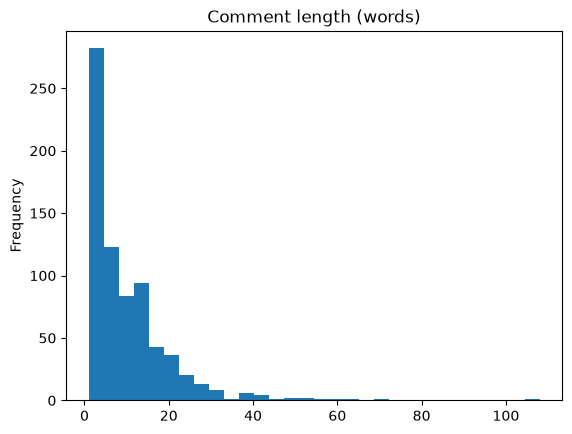

In [12]:
df["word_count"].plot.hist(bins=30, title="Comment length (words)")
plt.savefig(PLOTS / "comment_length_distribution.png")
plt.show()

## 5. Category distribution

In [13]:
category_counts = df["category"].value_counts()
category_counts

category
teaching              125
course_content        124
examination           122
library_facilities    118
extracurricular       118
labwork               117
Name: count, dtype: int64

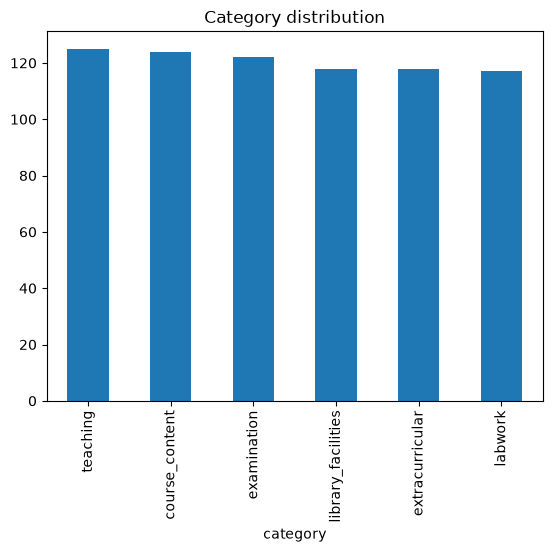

In [14]:
category_counts.plot.bar(title="Category distribution")
plt.savefig(PLOTS / "category_distribution.png", bbox_inches="tight")
plt.show()

## 6. Sentiment distribution

In [15]:
sentiment_counts = df["sentiment"].value_counts()
sentiment_counts

sentiment
positive    451
negative    139
neutral     134
Name: count, dtype: int64

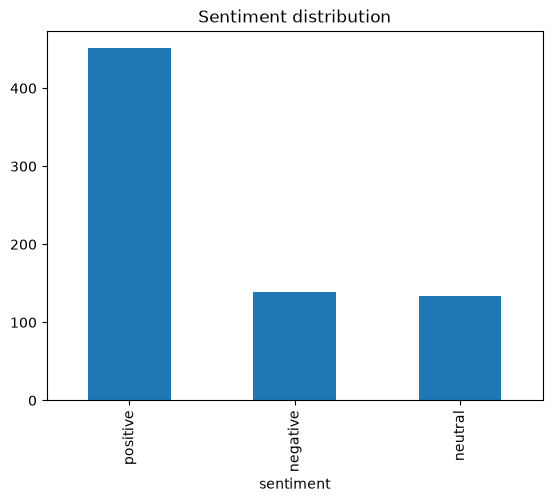

In [16]:
sentiment_counts.plot.bar(title="Sentiment distribution")
plt.savefig(PLOTS / "sentiment_distribution.png", bbox_inches="tight")
plt.show()

If one class is much larger than the others, accuracy will be misleading. Thus, we will report macro-F1.

Category × sentiment: are some categories mostly negative?

In [18]:
pd.crosstab(df["category"], df["sentiment"])

sentiment,negative,neutral,positive
category,,,
course_content,27,24,73
examination,22,29,71
extracurricular,12,15,91
labwork,36,14,67
library_facilities,29,23,66
teaching,13,29,83


## 7. Comments with possibly more than one idea

Heuristic: a contrast/addition word (*but, however, although, while, whereas, yet, also*) or two or more sentences. This gives a rough upper bound on how often single-label annotation is too coarse. It doesn't detect multi-theme comments reliably.

In [19]:
has_marker = df["text"].str.contains(r"\b(?:but|however|although|while|whereas|yet|also)\b", case=False)
many_sentences = df["text"].str.count(r"[.!?]") >= 2
df["possible_multi_idea"] = has_marker | many_sentences

df["possible_multi_idea"].sum()

np.int64(194)

In [23]:
df[df["possible_multi_idea"]].sample(15, random_state=42)

,text,category,sentiment_score,sentiment,word_count,is_empty,is_duplicate,is_very_short,possible_pii,possible_multi_idea
516,"good it is, but teachers do not consider the n...",extracurricular,0,neutral,11,False,False,False,False,True
64,teaching is good but some teachers are not abl...,teaching,0,neutral,24,False,False,False,False,True
576,Well... all the books are not avilable . If th...,library_facilities,-1,negative,25,False,False,False,False,True
338,yeah quite well but ... some of the books are ...,library_facilities,0,neutral,12,False,False,False,False,True
240,good but not good . sir improve the subject,teaching,0,neutral,9,False,False,False,False,True
571,The content of the courses are good but depth ...,course_content,0,neutral,19,False,False,False,False,True
183,examination including exam pattern is good in ...,examination,1,positive,18,False,False,False,False,True
60,Knowledge is maximum gained by reading books ...,course_content,1,positive,15,False,False,False,False,True
386,Evaluation method is gud.But the content is mo...,labwork,0,neutral,12,False,False,False,False,True
383,lab work is also good,labwork,1,positive,5,False,False,False,False,True


Read the sample above. How many really mention two aspects (e.g. teaching *and* assessment), or carry mixed sentiment (praise *but* complaint)? Write your count in the questions at the end.

## 8. Overlap between categories (TF-IDF)

Join all comments per category, vectorise with TF-IDF and compare categories with cosine similarity. High similarity suggests a blurry category boundary.

In [25]:
category_text = df.groupby("category")["text"].apply(" ".join)

tfidf = TfidfVectorizer(stop_words="english").fit_transform(category_text)
similarity = pd.DataFrame(cosine_similarity(tfidf), index=category_text.index, columns=category_text.index)

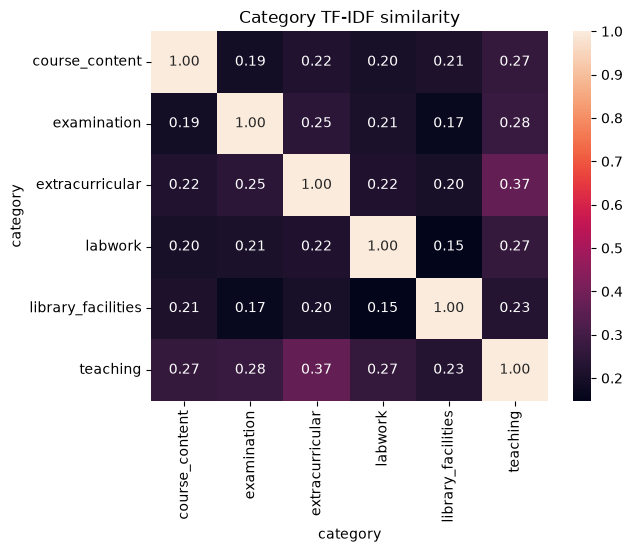

In [26]:
sns.heatmap(similarity, annot=True, fmt=".2f")
plt.title("Category TF-IDF similarity")
plt.savefig(PLOTS / "category_tfidf_similarity.png", bbox_inches="tight")
plt.show()

## 9. Save outputs

- `cleaned_feedback.csv`: drops empty comments and keeps all flag columns, so later days can filter (e.g. exclude very short comments or duplicates).
- Review queues for duplicates, very short comments, possible multi-idea comments and possible PII.

In [27]:
category_counts.to_csv(OUT / "category_distribution.csv")
sentiment_counts.to_csv(OUT / "sentiment_distribution.csv")

df[df["is_duplicate"]].to_csv(OUT / "duplicate_comments.csv", index=False)
df[df["is_very_short"]].to_csv(OUT / "very_short_comments.csv", index=False)
df[df["possible_multi_idea"]].to_csv(OUT / "possible_multi_idea_comments.csv", index=False)
df[df["possible_pii"]].to_csv(OUT / "pii_review_queue.csv", index=False)

df[~df["is_empty"]].to_csv(OUT / "cleaned_feedback.csv", index=False)

In [28]:
summary = f"""# Data Quality Summary

- Rows: {len(df)}
- Empty comments: {df["is_empty"].sum()}
- Rows in duplicate sets: {df["is_duplicate"].sum()}
- Very short comments (<= 3 words): {df["is_very_short"].sum()}
- Possible PII: {df["possible_pii"].sum()}
- Possible multi-idea comments: {df["possible_multi_idea"].sum()}
- Median length: {df["word_count"].median()} words

## Category distribution

{category_counts.to_string()}

## Sentiment distribution

{sentiment_counts.to_string()}
"""

(OUT / "data_quality_summary.md").write_text(summary)

485